# Multichannel ROI and calibration pairs

This notebook confirms the `MultichannelROI` on a source image, then calls the pipeline to read the calibration file list, crop, localize, pair each moving channel to channel 0, and merge pairs across files.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from smlm.camera import EMCCD
from smlm.io import load_raw
from smlm.multiplex import MultichannelROI

In [3]:
CALIB_FILES = [r"G:\PacBio\近观DNA_FRET\20261109\std2.sif",
               r"G:\PacBio\近观DNA_FRET\20261109\std.sif"]
if not Path(CALIB_FILES[0]).is_file():
    raise FileNotFoundError(f"SIF file not found: {CALIB_FILES[0]}")
raw = load_raw(CALIB_FILES[0])
camera = EMCCD(conv_factor=5.75, em_gain=300)
stack = camera.process(raw)
print(f"ImageStack: {stack.shape}, pixel_size={stack.pixel_size}")

ImageStack: (10, 512, 512), pixel_size=None


In [4]:
height, width = stack.shape[1:]
split_x = 256
ROI_Y = (0, height)
ROI_X = (0+10, split_x-10)
CHANNEL_OFFSETS = ((0, 0), (0, split_x))  # (dy, dx), relative to channel 0
CHANNELS = ("g", "r")

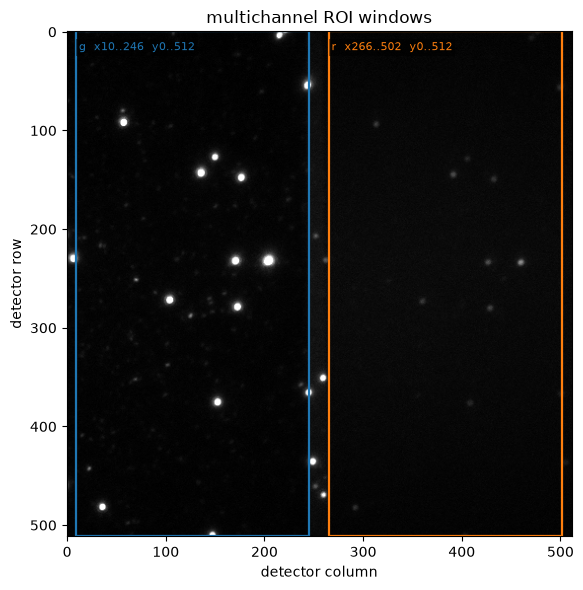

In [5]:
roi = MultichannelROI(
    y=ROI_Y,
    x=ROI_X,
    offsets=CHANNEL_OFFSETS,
    channels=CHANNELS,
)
show = roi.show_roi(stack)

## Validate the ROI and generate merged pairs

First confirm the crop on the initial file. The pipeline then uses its built-in calibration defaults and returns a channel-aligned list of merged `PairSet`s; the reference channel slot is `None`.

In [6]:
from smlm.multiplex import pair_multichannel_files

PAIR_REFERENCE = CHANNELS[0]
multiChannelPairs = pair_multichannel_files(
    CALIB_FILES, roi, reference=PAIR_REFERENCE)
#multiChannelPairs

--- [1/2] std2.sif
  localizations: g=23, r=10
  [r -> g] tol=  6.0 px ->    10 pairs, shift=(+0.12, -1.38) px
  [r -> g] 10 pairs
--- [2/2] std.sif
  localizations: g=35, r=12
  [r -> g] tol=  6.0 px ->    12 pairs, shift=(+0.10, -1.35) px
  [r -> g] 12 pairs
--- merged r -> g: 22 pairs from 2 files


## Fit registration per moving channel

The reference is taken from the `None` slot produced by `pair_multichannel_files`, so fitting uses the same reference as pairing. Each calibration records the ROI windows and offsets, source files, and moving/reference channel names.

In [7]:
from smlm.multiplex import fit_multichannel_pairs

multiChannelCalibrations = fit_multichannel_pairs(multiChannelPairs, roi)
multiChannelCalibrations

--- fitting r -> g
  交叉验证选阶 (指标 cv_p84_px):
    order 1  ( 3 参数)  med 0.086  p84 0.129  rms 0.121  max 0.372 px
    order 2  ( 6 参数)  med 0.084  p84 0.126  rms 0.115  max 0.327 px
    order 3  (10 参数)  med 0.093  p84 0.183  rms 0.151  max 0.353 px
    -> 选 order 1
  iter 0: kept    22/   22   thr=0.21 px   median=0.077 px
  iter 1: kept    21/   22   thr=0.17 px   median=0.060 px
  多项式阶数 = 1  (3 参数)
  poly  : median 0.060 px   rms 0.074 px
  affine: median 0.060 px   rms 0.074 px


[None, DualViewCalibration(r->g, order=1, coarse=(0, 256))]

## Save multichannel calibration


In [8]:
from smlm.multiplex import MultiChannelCalibrationBundle

MULTICHANNEL_CALIBRATION_PATH = Path(CALIB_FILES[0]).with_name(
    f"{Path(CALIB_FILES[0]).stem}_multichannel_calibration.npz"
)
multiChannelCalibrationBundle = MultiChannelCalibrationBundle.from_fit(
    multiChannelCalibrations, roi, CALIB_FILES)
multiChannelCalibrationBundle.save(MULTICHANNEL_CALIBRATION_PATH)

WindowsPath('G:/PacBio/近观DNA_FRET/20261109/std2_multichannel_calibration.npz')

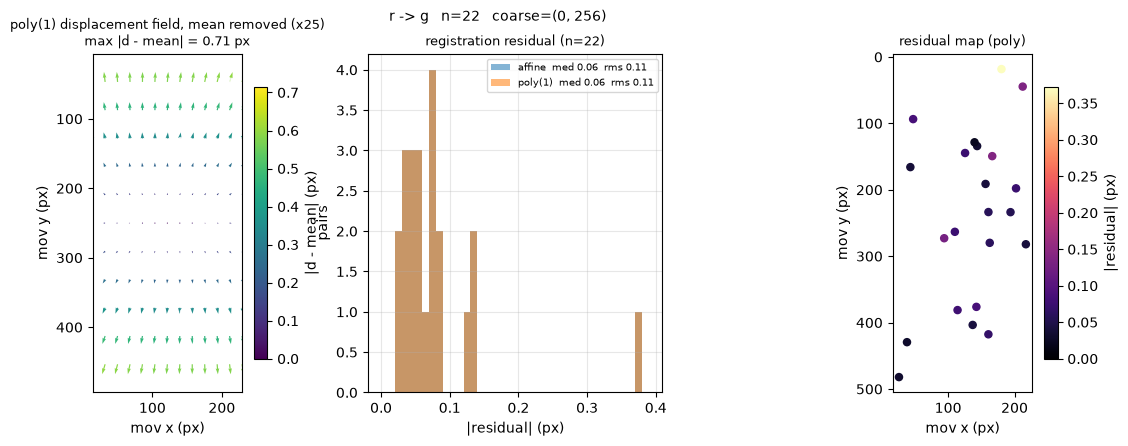

In [9]:
from smlm.multiplex import plot_overview

for channel_index, calibration in enumerate(multiChannelCalibrations):
    if calibration is not None:
        plot_overview(calibration, multiChannelPairs[channel_index])
plt.show()